In [1]:
# Imports and configuration
import os, re, time, json, hashlib, random
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc,
    precision_recall_curve, average_precision_score, roc_auc_score
)
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt

SEED = 42
CLASSES = ["CNV", "DME", "DRUSEN", "NORMAL"]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASSES)}
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 2
BASELINE_EPOCHS = 5
HYBRID_EPOCHS = 8
PATIENCE = 2
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
USE_PRETRAINED = True
OUTPUT_DIR = Path("/kaggle/working/oct_task2_final")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE)
if USE_AMP:
    print("GPU:", torch.cuda.get_device_name(0))

# Locate the folder containing train/, val/, and test/.
KNOWN_ROOTS = [
    Path("/kaggle/input/datasets/paultimothymooney/kermany2018/OCT2017"),
    Path("/kaggle/input/datasets/paultimothymooney/kermany2018/oct2017/OCT2017"),
    Path("/kaggle/input/OCT2017"),
]
def valid_root(p):
    return p.is_dir() and all((p / s).is_dir() for s in ("train", "val", "test"))

DATA_DIR = next((p for p in KNOWN_ROOTS if valid_root(p)), None)
if DATA_DIR is None:
    for root, dirs, files in os.walk("/kaggle/input"):
        candidate = Path(root)
        if valid_root(candidate):
            DATA_DIR = candidate
            break
        depth = len(candidate.parts) - len(Path("/kaggle/input").parts)
        if depth >= 10:
            dirs[:] = []

if DATA_DIR is None:
    raise FileNotFoundError(
        "OCT2017 root not found. Set DATA_DIR to the folder containing train/, val/, and test/."
    )
print("Dataset:", DATA_DIR)

Device: cuda
GPU: Tesla T4
Dataset: /kaggle/input/datasets/paultimothymooney/kermany2018/OCT2017 


In [2]:

# data audit 

import os
import re
import json
import hashlib
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, wait, FIRST_COMPLETED

import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedGroupKFold


EXTENSIONS = {".jpg", ".jpeg", ".png"}

FILENAME_RE = re.compile(
    r"^(CNV|DME|DRUSEN|NORMAL)-(\d+)-(\d+)\.(jpg|jpeg|png)$",
    re.IGNORECASE
)

# Adjust these only if necessary.
MAX_WORKERS = 4
MAX_PENDING = MAX_WORKERS * 4
CACHE_FILE = OUTPUT_DIR / "oct_sha256_cache.jsonl"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

required_variables = [
    "DATA_DIR",
    "CLASS_TO_ID",
    "CLASSES",
    "SEED"
]

for variable in required_variables:
    if variable not in globals():
        raise NameError(f"Required variable is missing: {variable}")

DATA_DIR = Path(DATA_DIR)

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dataset directory not found: {DATA_DIR}")

for split_name in ("train", "val", "test"):
    if not (DATA_DIR / split_name).exists():
        raise FileNotFoundError(
            f"Missing original dataset folder: {DATA_DIR / split_name}"
        )

print("Dataset directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)
print("Hash workers:", MAX_WORKERS)



def sha256_file(path, chunk_size=1024 * 1024):
    """Calculate SHA-256 hash without loading the whole image into RAM."""

    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(chunk_size), b""):
            digest.update(chunk)

    return digest.hexdigest()


#LOAD EXISTING HASH CACHE


# Cache key uses file path, size and modification timestamp.
# Unchanged files can reuse their previously calculated hashes.

hash_cache = {}

if CACHE_FILE.exists():

    print("\nLoading previous hash cache...")

    with open(CACHE_FILE, "r") as cache_file:

        for line in cache_file:

            try:
                record = json.loads(line)

                hash_cache[record["cache_key"]] = record["sha256"]

            except (json.JSONDecodeError, KeyError):
                continue

print("Cached hashes:", len(hash_cache))


# COLLECT IMAGE PATHS


candidates = []
unreadable = []
unparsed = []

print("\nCollecting image paths...")

for original_split in ("train", "val", "test"):

    split_dir = DATA_DIR / original_split

    for path in split_dir.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in EXTENSIONS:
            continue

        label = path.parent.name.upper()

        if label not in CLASS_TO_ID:
            continue

        match = FILENAME_RE.match(path.name)

        if match is None:

            unparsed.append(str(path))
            continue

        file_label, patient_id, image_number, _ = match.groups()

        if file_label.upper() != label:

            raise ValueError(
                f"Filename/folder label mismatch: {path}"
            )

        try:

            stat = path.stat()

        except OSError as exc:

            unreadable.append({
                "path": str(path),
                "error": str(exc)
            })

            continue

        cache_key = (
            f"{path.resolve()}|"
            f"{stat.st_size}|"
            f"{stat.st_mtime_ns}"
        )

        candidates.append({

            "path": str(path),
            "filename": path.name,
            "original_split": original_split,
            "label": label,
            "label_id": CLASS_TO_ID[label],
            "patient_id": str(patient_id),
            "image_number": int(image_number),
            "cache_key": cache_key

        })


if unparsed:

    raise ValueError(
        f"{len(unparsed)} image filenames do not match "
        "the expected Kermany naming pattern. "
        f"Examples: {unparsed[:5]}. "
        "Inspect these files before splitting."
    )

if not candidates:

    raise RuntimeError("No OCT images found in the dataset folders.")

print("Total candidate images:", len(candidates))


# IMAGE VALIDATION AND HASHING

def process_image(item):

    """Validate one image and calculate its exact SHA-256 hash."""

    try:

        with Image.open(item["path"]) as image:
            image.verify()

        file_hash = sha256_file(item["path"])

        return {
            "cache_key": item["cache_key"],
            "sha256": file_hash,
            "error": None
        }

    except Exception as exc:

        return {
            "cache_key": item["cache_key"],
            "sha256": None,
            "error": str(exc)
        }


# Reuse successful hashes from previous executions.
rows = []

pending_items = []

for item in candidates:

    cached_hash = hash_cache.get(item["cache_key"])

    if cached_hash is not None:

        rows.append({

            "path": item["path"],
            "filename": item["filename"],
            "original_split": item["original_split"],
            "label": item["label"],
            "label_id": item["label_id"],
            "patient_id": item["patient_id"],
            "image_number": item["image_number"],
            "sha256": cached_hash

        })

    else:

        pending_items.append(item)


cached_count = len(rows)

print("\nPreviously cached images:", cached_count)
print("Images requiring validation and hashing:", len(pending_items))

# Bounded parallel execution:
# avoids submitting the entire dataset to the executor at once.

with open(CACHE_FILE, "a") as cache_out:

    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:

        pending_futures = {}
        item_iterator = iter(pending_items)

        def submit_next():

            try:
                item = next(item_iterator)

            except StopIteration:
                return False

            future = executor.submit(process_image, item)

            pending_futures[future] = item

            return True

        # Initially submit only a limited number of jobs.
        for _ in range(min(MAX_PENDING, len(pending_items))):
            submit_next()

        with tqdm(
            total=len(candidates),
            initial=cached_count,
            desc="Validating and hashing OCT images",
            unit="image"
        ) as progress:

            while pending_futures:

                completed, _ = wait(
                    pending_futures,
                    return_when=FIRST_COMPLETED
                )

                for future in completed:

                    item = pending_futures.pop(future)

                    result = future.result()

                    # Save successful hashes immediately.
                    if result["error"] is None:

                        cache_record = {
                            "cache_key": result["cache_key"],
                            "sha256": result["sha256"]
                        }

                        cache_out.write(
                            json.dumps(cache_record) + "\n"
                        )

                        cache_out.flush()

                        rows.append({

                            "path": item["path"],
                            "filename": item["filename"],
                            "original_split": item["original_split"],
                            "label": item["label"],
                            "label_id": item["label_id"],
                            "patient_id": item["patient_id"],
                            "image_number": item["image_number"],
                            "sha256": result["sha256"]

                        })

                    else:

                        unreadable.append({

                            "path": item["path"],
                            "error": result["error"]

                        })

                    progress.update(1)

                    # Submit another task when one finishes.
                    submit_next()


# CREATE RAW DATAFRAME


if not rows:

    raise RuntimeError("No readable OCT images found.")

raw_df = (
    pd.DataFrame(rows)
    .drop_duplicates("path")
    .reset_index(drop=True)
)

print("\nImage scanning completed.")
print("Readable images:", len(raw_df))
print("Unreadable images:", len(unreadable))
print("Cached images:", cached_count)



# PATIENT GROUPING USING UNION-FIND


# Patients sharing an exact duplicate image are connected.
# This prevents duplicate-linked patient IDs from crossing splits.

parent = {
    patient: patient
    for patient in raw_df["patient_id"].unique()
}


def find(x):

    while parent[x] != x:

        parent[x] = parent[parent[x]]

        x = parent[x]

    return x


def union(a, b):

    root_a = find(a)
    root_b = find(b)

    if root_a != root_b:

        parent[root_b] = root_a


print("\nConnecting patients that share exact duplicate images...")

duplicate_patient_links = 0

for _, group in tqdm(
    raw_df.groupby("sha256", sort=False),
    desc="Grouping duplicate-linked patients"
):

    ids = group["patient_id"].unique().tolist()

    if len(ids) > 1:

        for other in ids[1:]:

            union(ids[0], other)

            duplicate_patient_links += 1


# REMOVE CONFLICTING LABELS AND EXACT DUPLICATES


print("\nChecking duplicate hashes and conflicting labels...")

hash_label_counts = (
    raw_df.groupby("sha256")["label"]
    .nunique()
)

conflicting_hashes = set(
    hash_label_counts[
        hash_label_counts > 1
    ].index
)

conflict_rows = raw_df[
    raw_df["sha256"].isin(conflicting_hashes)
].copy()

# Remove exact images associated with conflicting class labels.
clean_df = raw_df[
    ~raw_df["sha256"].isin(conflicting_hashes)
].copy()

# Keep one copy of each exact image.
clean_df = (
    clean_df.sort_values("path")
    .drop_duplicates("sha256", keep="first")
    .copy()
)

# Assign connected patient/source group IDs.
clean_df["group_id"] = (
    clean_df["patient_id"].map(find)
)

if clean_df.empty:

    raise RuntimeError(
        "No images remain after duplicate/conflict removal."
    )

print("Conflicting hashes removed:", len(conflicting_hashes))
print("Images removed due to conflicting labels:", len(conflict_rows))
print("Images after deduplication:", len(clean_df))
print("Unique patient/source groups:", clean_df["group_id"].nunique())


#AUDIT ORIGINAL FOLDER PATIENT OVERLAP


original_patient_sets = {

    split: set(
        raw_df.loc[
            raw_df["original_split"] == split,
            "patient_id"
        ]
    )

    for split in ("train", "val", "test")

}

original_overlap = {

    "train_test_patient_overlap": len(
        original_patient_sets["train"]
        & original_patient_sets["test"]
    ),

    "train_val_patient_overlap": len(
        original_patient_sets["train"]
        & original_patient_sets["val"]
    ),

    "val_test_patient_overlap": len(
        original_patient_sets["val"]
        & original_patient_sets["test"]
    )

}

print("\nOriginal folder patient overlap:")
print(original_overlap)


#CHECK DATASET CLASS AVAILABILITY


expected_classes = set(CLASSES)

available_classes = set(clean_df["label"])

missing_classes = expected_classes - available_classes

if missing_classes:

    raise RuntimeError(
        f"Classes missing after cleaning: {missing_classes}"
    )

group_count = clean_df["group_id"].nunique()

if group_count < 10:

    raise RuntimeError(
        "Not enough independent patient groups for "
        "the requested 10-fold outer grouped split."
    )


#HELPER: SELECT A STRATIFIED GROUPED FOLD

def choose_grouped_fold(
    dataframe,
    n_splits,
    random_state,
    target_fraction
):

    """
    Select a grouped fold that:
    1. Keeps all patient groups intact.
    2. Contains every class in both partitions.
    3. Has a holdout size close to the requested fraction.
    4. Has a class distribution close to the full dataset.
    """

    splitter = StratifiedGroupKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state
    )

    y = dataframe["label_id"]
    groups = dataframe["group_id"]

    all_classes = set(dataframe["label_id"].unique())

    overall_distribution = (
        dataframe["label_id"]
        .value_counts(normalize=True)
        .sort_index()
    )

    best_candidate = None
    best_score = float("inf")

    for train_indices, holdout_indices in splitter.split(
        dataframe,
        y,
        groups
    ):

        train_part = dataframe.iloc[train_indices]
        holdout_part = dataframe.iloc[holdout_indices]

        train_classes = set(train_part["label_id"].unique())
        holdout_classes = set(holdout_part["label_id"].unique())

        # Both partitions must contain all classes.
        if train_classes != all_classes:
            continue

        if holdout_classes != all_classes:
            continue

        actual_fraction = (
            len(holdout_part) / len(dataframe)
        )

        holdout_distribution = (
            holdout_part["label_id"]
            .value_counts(normalize=True)
            .reindex(overall_distribution.index, fill_value=0)
        )

        distribution_error = (
            holdout_distribution - overall_distribution
        ).abs().mean()

        size_error = abs(
            actual_fraction - target_fraction
        )

        score = size_error + distribution_error

        if score < best_score:

            best_score = score

            best_candidate = (
                train_indices,
                holdout_indices
            )

    if best_candidate is None:

        raise RuntimeError(
            f"Could not create a valid {n_splits}-fold "
            "patient-grouped split with all classes represented. "
            "Inspect patient counts and class distribution."
        )

    return best_candidate


# outer split  approxx 90% train + val n 10 % test


print("\nCreating patient-grouped test split...")

trainval_idx, test_idx = choose_grouped_fold(
    dataframe=clean_df,
    n_splits=10,
    random_state=SEED,
    target_fraction=0.10
)

trainval_df = clean_df.iloc[trainval_idx].copy()

test_df = clean_df.iloc[test_idx].copy()


# inner split = 80 % train w 10% val

print("Creating patient-grouped validation split...")

train_idx, val_idx = choose_grouped_fold(
    dataframe=trainval_df,
    n_splits=9,
    random_state=SEED + 1,
    target_fraction=1 / 9
)

train_df = trainval_df.iloc[train_idx].copy()

val_df = trainval_df.iloc[val_idx].copy()


#combine final split


train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

manifest = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

manifest = manifest.sort_values(
    ["split", "label", "path"]
).reset_index(drop=True)


#hard leakage chk


print("\nRunning patient and duplicate leakage checks...")

split_names = ("train", "val", "test")

group_sets = {

    split: set(
        manifest.loc[
            manifest["split"] == split,
            "group_id"
        ]
    )

    for split in split_names

}

hash_sets = {

    split: set(
        manifest.loc[
            manifest["split"] == split,
            "sha256"
        ]
    )

    for split in split_names

}


# Patient/source group checks.
assert group_sets["train"].isdisjoint(group_sets["val"])
assert group_sets["train"].isdisjoint(group_sets["test"])
assert group_sets["val"].isdisjoint(group_sets["test"])


# Exact duplicate checks.
assert hash_sets["train"].isdisjoint(hash_sets["val"])
assert hash_sets["train"].isdisjoint(hash_sets["test"])
assert hash_sets["val"].isdisjoint(hash_sets["test"])


# Check that all expected classes appear in every split.
for split_name in split_names:

    present = set(
        manifest.loc[
            manifest["split"] == split_name,
            "label"
        ]
    )

    if present != expected_classes:

        raise RuntimeError(
            f"{split_name} is missing classes: "
            f"{expected_classes - present}"
        )


# Check that no duplicate hashes remain in the manifest.
assert manifest["sha256"].is_unique

print("Patient-group overlap: ZERO")
print("Exact-hash overlap: ZERO")
print("All classes present in all splits: YES")




manifest_path = OUTPUT_DIR / "patient_grouped_manifest.csv"

manifest.to_csv(
    manifest_path,
    index=False
)

split_summary = (
    manifest.groupby("split")
    .agg(
        images=("path", "count"),
        patient_groups=("group_id", "nunique")
    )
    .reindex(["train", "val", "test"])
    .reset_index()
)

class_counts = pd.crosstab(
    manifest["split"],
    manifest["label"]
).reindex(
    index=["train", "val", "test"],
    columns=CLASSES,
    fill_value=0
)

class_percentages = (
    class_counts
    .div(class_counts.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)



split_summary.to_csv(
    OUTPUT_DIR / "split_summary.csv",
    index=False
)

class_counts.to_csv(
    OUTPUT_DIR / "class_split_counts.csv"
)

class_percentages.to_csv(
    OUTPUT_DIR / "class_split_percentages.csv"
)

pd.DataFrame(unreadable).to_csv(
    OUTPUT_DIR / "unreadable_files.csv",
    index=False
)

conflict_rows.to_csv(
    OUTPUT_DIR / "conflicting_hash_labels_removed.csv",
    index=False
)


#SAVE DATA INTEGRITY AUDIT


audit = {

    "dataset_root": str(DATA_DIR),

    "seed": int(SEED),

    "split_strategy": (
        "StratifiedGroupKFold: approximately "
        "80/10/10 by patient/source group"
    ),

    "hash_algorithm": "SHA-256",

    "raw_readable_images": int(len(raw_df)),

    "clean_images": int(len(manifest)),

    "unreadable_images_removed": int(len(unreadable)),

    "conflicting_label_hashes_removed": int(
        len(conflicting_hashes)
    ),

    "patient_groups": int(
        manifest["group_id"].nunique()
    ),

    "exact_duplicate_images_removed": int(
        len(raw_df)
        - len(conflict_rows)
        - len(clean_df)
    ),

    "original_folder_patient_overlap": original_overlap,

    "patient_group_overlap_after_split": {

        "train_val": 0,
        "train_test": 0,
        "val_test": 0

    },

    "exact_hash_overlap_after_split": {

        "train_val": 0,
        "train_test": 0,
        "val_test": 0

    },

    "split_image_counts": {

        split: int(
            (manifest["split"] == split).sum()
        )

        for split in split_names

    }

}


with open(
    OUTPUT_DIR / "data_integrity_audit.json",
    "w"
) as audit_file:

    json.dump(
        audit,
        audit_file,
        indent=4
    )


#FINAL REPORT

print("\n" + "=" * 60)
print("DATA INTEGRITY AUDIT COMPLETED")
print("=" * 60)

print("\nOriginal folder patient overlap:")
print(original_overlap)

print("\nReadable images:", len(raw_df))
print("Final clean images:", len(manifest))
print("Unreadable images:", len(unreadable))
print("Conflicting hashes removed:", len(conflicting_hashes))
print("Patient/source groups:", manifest["group_id"].nunique())

print("\nFinal split percentages:")

for split in split_names:

    count = (
        manifest["split"] == split
    ).sum()

    percentage = (
        count / len(manifest)
    ) * 100

    print(
        f"{split.upper():5s}: "
        f"{count:,} images ({percentage:.2f}%)"
    )


print("\nPatient-group leakage: ZERO")
print("Exact-image hash leakage: ZERO")
print("Missing classes: ZERO")

print("\nLeakage-safe split: PASS")

print("\nSaved files:")

print("Manifest:", manifest_path)

print(
    "Audit:",
    OUTPUT_DIR / "data_integrity_audit.json"
)

print(
    "Hash cache:",
    CACHE_FILE
)

display(split_summary)
display(class_counts)
display(class_percentages)

print("\nAll audit files saved successfully.")


Dataset directory: /kaggle/input/datasets/paultimothymooney/kermany2018/OCT2017 
Output directory: /kaggle/working/oct_task2_final
Hash workers: 4
Cached hashes: 0

Total candidate images: 84484

Previously cached images: 0
Images requiring validation and hashing: 84484


Validating and hashing OCT images:   0%|          | 0/84484 [00:00<?, ?image/s]


Image scanning completed.
Readable images: 84484
Unreadable images: 0
Cached images: 0

Connecting patients that share exact duplicate images...


Grouping duplicate-linked patients:   0%|          | 0/76902 [00:00<?, ?it/s]


Checking duplicate hashes and conflicting labels...
Conflicting hashes removed: 225
Images removed due to conflicting labels: 466
Images after deduplication: 76677
Unique patient/source groups: 4656

Original folder patient overlap:
{'train_test_patient_overlap': 546, 'train_val_patient_overlap': 21, 'val_test_patient_overlap': 1}

Creating patient-grouped test split...
Creating patient-grouped validation split...

Running patient and duplicate leakage checks...
Patient-group overlap: ZERO
Exact-hash overlap: ZERO
All classes present in all splits: YES

DATA INTEGRITY AUDIT COMPLETED

Original folder patient overlap:
{'train_test_patient_overlap': 546, 'train_val_patient_overlap': 21, 'val_test_patient_overlap': 1}

Readable images: 84484
Final clean images: 76677
Unreadable images: 0
Conflicting hashes removed: 225
Patient/source groups: 4656

Final split percentages:
TRAIN: 61,390 images (80.06%)
VAL  : 7,378 images (9.62%)
TEST : 7,909 images (10.31%)

Patient-group leakage: ZERO
E

,split,images,patient_groups
0,train,61390,3733
1,val,7378,459
2,test,7909,464


label,CNV,DME,DRUSEN,NORMAL
split,,,,
train,24999,9115,6258,21018
val,2980,870,907,2621
test,3461,1132,668,2648


label,CNV,DME,DRUSEN,NORMAL
split,,,,
train,40.72,14.85,10.19,34.24
val,40.39,11.79,12.29,35.52
test,43.76,14.31,8.45,33.48



All audit files saved successfully.


In [3]:
#Preprocessing and dataloaders
# Image transforms and loaders
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(7),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

class OCTDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row.path) as image:
            image = image.convert("RGB")
        return self.transform(image), int(row.label_id)

train_ds = OCTDataset(train_df, train_transform)
val_ds = OCTDataset(val_df, eval_transform)
test_ds = OCTDataset(test_df, eval_transform)

loader_args = dict(
    batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0)
)
train_loader = DataLoader(train_ds, shuffle=True, **loader_args)
val_loader = DataLoader(val_ds, shuffle=False, **loader_args)
test_loader = DataLoader(test_ds, shuffle=False, **loader_args)

weights_np = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASSES)),
    y=train_df.label_id.to_numpy()
)
CLASS_WEIGHTS = torch.tensor(weights_np, dtype=torch.float32, device=DEVICE)
CRITERION = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS)
print("Class weights:", dict(zip(CLASSES, weights_np.round(3))))
print("Images:", len(train_ds), "train |", len(val_ds), "validation |", len(test_ds), "test")

Class weights: {'CNV': np.float64(0.614), 'DME': np.float64(1.684), 'DRUSEN': np.float64(2.452), 'NORMAL': np.float64(0.73)}
Images: 61390 train | 7378 validation | 7909 test


In [4]:
#Training n evaluation utilities
def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

@torch.no_grad()
def predict(model, loader):
    model.eval()
    y_true, y_prob = [], []
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        logits = model(images)
        y_prob.extend(torch.softmax(logits.float(), dim=1).cpu().numpy())
        y_true.extend(labels.numpy())
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    # Includes data loading, host-to-device transfer, and model execution
    # (end-to-end test pipeline latency, not isolated GPU kernel latency).
    return np.asarray(y_true), np.asarray(y_prob), elapsed

def evaluate_model(model, model_name):
    y_true, y_prob, inference_seconds = predict(model, test_loader)
    y_pred = y_prob.argmax(axis=1)
    report = classification_report(
        y_true, y_pred, labels=np.arange(len(CLASSES)),
        target_names=CLASSES, output_dict=True, zero_division=0
    )
    p_macro, r_macro, f_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    p_weighted, r_weighted, f_weighted, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    y_bin = np.eye(len(CLASSES))[y_true]

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(CLASSES)))
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(f"{model_name} — Confusion Matrix")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{model_name}_confusion_matrix.png", dpi=160)
    plt.show()
    print("Reading: Diagonal cells are correct predictions; off-diagonal cells show which classes are confused.")

    # One-vs-rest ROC
    per_class_auc, per_class_ap = {}, {}
    fig, ax = plt.subplots(figsize=(8, 6))
    for i, name in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
        per_class_auc[name] = roc_auc_score(y_bin[:, i], y_prob[:, i])
        ax.plot(fpr, tpr, label=f"{name} (AUC={per_class_auc[name]:.3f})")
    ax.plot([0, 1], [0, 1], "--", label="Chance")
    ax.set_title(f"{model_name} — One-vs-Rest ROC Curves")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{model_name}_roc_ovr.png", dpi=160)
    plt.show()
    print("Reading: A curve closer to the upper-left and a larger AUC indicate better class discrimination.")

    # One-vs-rest precision-recall
    fig, ax = plt.subplots(figsize=(8, 6))
    supports = []
    for i, name in enumerate(CLASSES):
        precision, recall, _ = precision_recall_curve(y_bin[:, i], y_prob[:, i])
        per_class_ap[name] = average_precision_score(y_bin[:, i], y_prob[:, i])
        supports.append(int(y_bin[:, i].sum()))
        ax.plot(recall, precision, label=f"{name} (AP={per_class_ap[name]:.3f})")
    ax.set_title(f"{model_name} — One-vs-Rest Precision–Recall Curves")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend(loc="best")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{model_name}_pr_ovr.png", dpi=160)
    plt.show()
    print("Reading: Higher precision at the same recall is better; AP summarizes each class curve.")
    print("Timing note: milliseconds/image includes test data loading, transfer, and model execution.")

    result = {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": p_macro, "macro_recall": r_macro, "macro_f1": f_macro,
        "weighted_precision": p_weighted, "weighted_recall": r_weighted,
        "weighted_f1": f_weighted,
        "macro_roc_auc_ovr": roc_auc_score(y_true, y_prob, average="macro", multi_class="ovr"),
        "weighted_roc_auc_ovr": roc_auc_score(y_true, y_prob, average="weighted", multi_class="ovr"),
        "macro_average_precision_ovr": float(np.mean(list(per_class_ap.values()))),
        "weighted_average_precision_ovr": float(np.average(list(per_class_ap.values()), weights=supports)),
        "inference_ms_per_image": inference_seconds * 1000 / len(test_ds)
    }
    for name in CLASSES:
        result[f"{name}_precision"] = report[name]["precision"]
        result[f"{name}_recall"] = report[name]["recall"]
        result[f"{name}_f1"] = report[name]["f1-score"]
        result[f"{name}_roc_auc"] = per_class_auc[name]
        result[f"{name}_average_precision"] = per_class_ap[name]

    pd.DataFrame(report).T.to_csv(OUTPUT_DIR / f"{model_name}_classification_report.csv")
    return result, cm

def train_model(model, model_name, epochs):
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(
        (p for p in model.parameters() if p.requires_grad),
        lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    best_f1, stale = -1.0, 0
    checkpoint = OUTPUT_DIR / f"{model_name}_best.pt"
    history = []
    start_all = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum, seen = 0.0, 0
        start_epoch = time.perf_counter()
        for images, labels in train_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = model(images)
                loss = CRITERION(logits, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            loss_sum += loss.item() * labels.size(0)
            seen += labels.size(0)

        val_true, val_prob, _ = predict(model, val_loader)
        val_f1 = precision_recall_fscore_support(
            val_true, val_prob.argmax(1), average="macro", zero_division=0
        )[2]
        history.append({
            "epoch": epoch, "train_loss": loss_sum / seen,
            "validation_macro_f1": val_f1
        })
        print(
            f"{model_name} | epoch {epoch}/{epochs} | "
            f"loss={loss_sum/seen:.4f} | val_macro_F1={val_f1:.4f} | "
            f"minutes={(time.perf_counter()-start_epoch)/60:.1f}"
        )
        if val_f1 > best_f1:
            best_f1, stale = val_f1, 0
            torch.save(model.state_dict(), checkpoint)
        else:
            stale += 1
            if stale >= PATIENCE:
                print("Early stopping.")
                break

    training_seconds = time.perf_counter() - start_all
    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE))
    pd.DataFrame(history).to_csv(OUTPUT_DIR / f"{model_name}_history.csv", index=False)
    return model, training_seconds, checkpoint

\n====================================================================== \nTraining: MobileNetV2
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 119MB/s] 
/tmp/ipykernel_120/844640498.py:120: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


MobileNetV2 | epoch 1/5 | loss=0.2971 | val_macro_F1=0.9371 | minutes=5.3


/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


MobileNetV2 | epoch 2/5 | loss=0.1774 | val_macro_F1=0.9451 | minutes=4.8


/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


MobileNetV2 | epoch 3/5 | loss=0.1454 | val_macro_F1=0.9456 | minutes=4.8


/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


MobileNetV2 | epoch 4/5 | loss=0.1276 | val_macro_F1=0.9427 | minutes=4.8


/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


MobileNetV2 | epoch 5/5 | loss=0.1111 | val_macro_F1=0.9530 | minutes=4.8


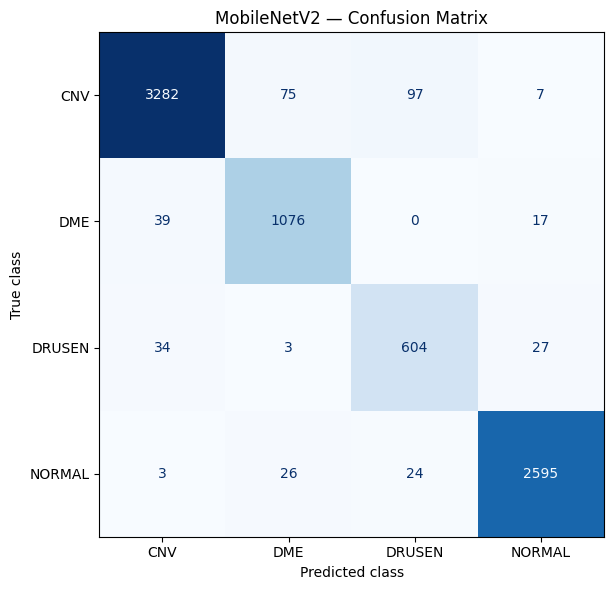

Reading: Diagonal cells are correct predictions; off-diagonal cells show which classes are confused.


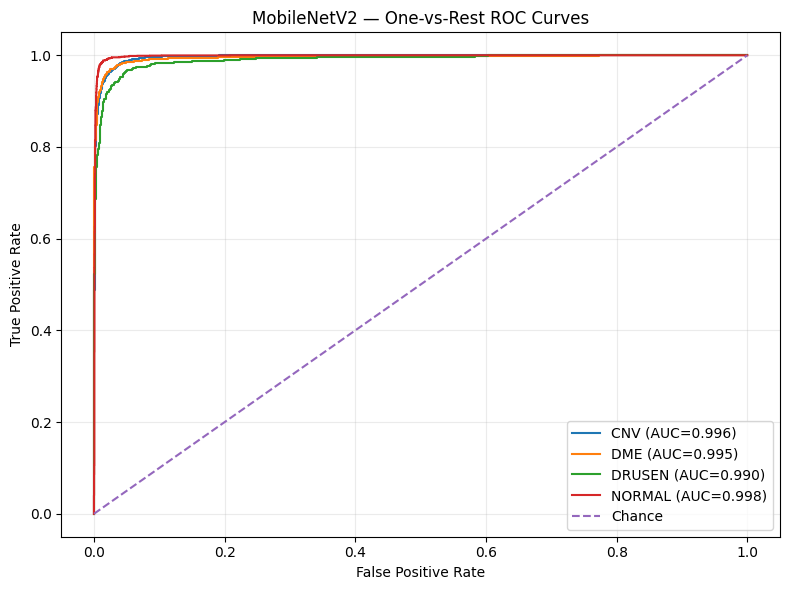

Reading: A curve closer to the upper-left and a larger AUC indicate better class discrimination.


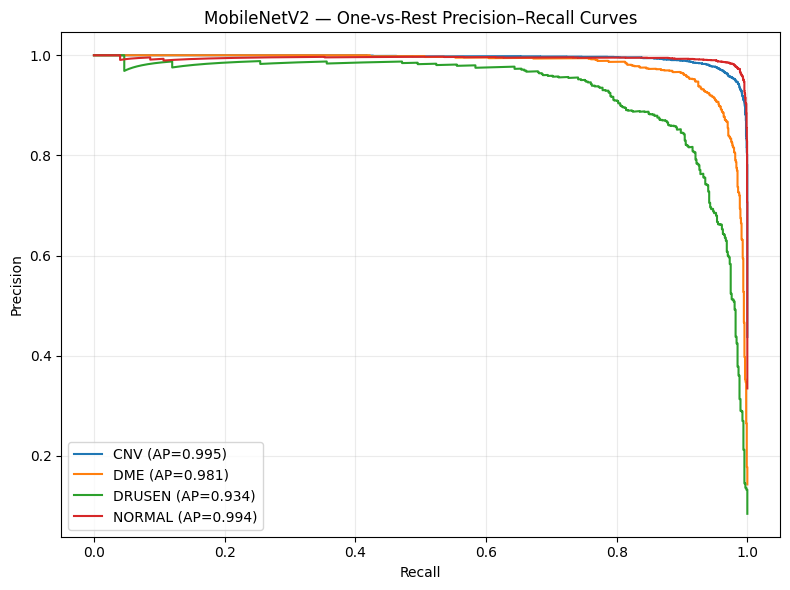

Reading: Higher precision at the same recall is better; AP summarizes each class curve.
Timing note: milliseconds/image includes test data loading, transfer, and model execution.
\n====================================================================== \nTraining: ResNet50
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 231MB/s]
/tmp/ipykernel_120/844640498.py:120: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


ResNet50 | epoch 1/5 | loss=0.2529 | val_macro_F1=0.9328 | minutes=5.3


/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


ResNet50 | epoch 2/5 | loss=0.1541 | val_macro_F1=0.9260 | minutes=5.3


/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


ResNet50 | epoch 3/5 | loss=0.1289 | val_macro_F1=0.9399 | minutes=5.3


/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


ResNet50 | epoch 4/5 | loss=0.1114 | val_macro_F1=0.9411 | minutes=5.3


/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


ResNet50 | epoch 5/5 | loss=0.0979 | val_macro_F1=0.9491 | minutes=5.3


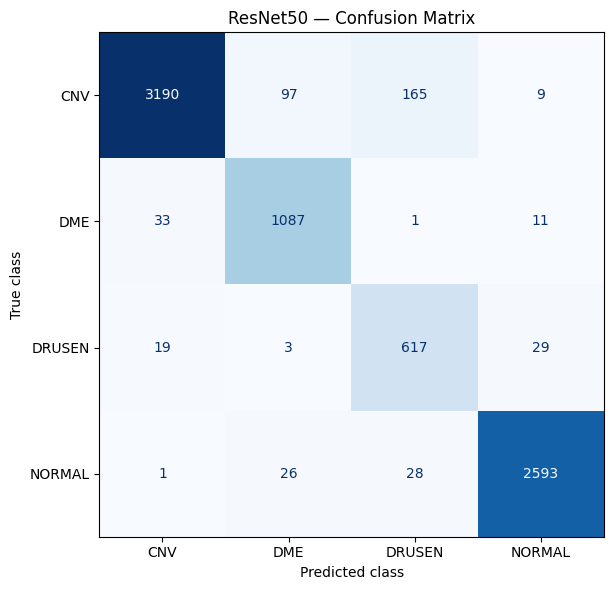

Reading: Diagonal cells are correct predictions; off-diagonal cells show which classes are confused.


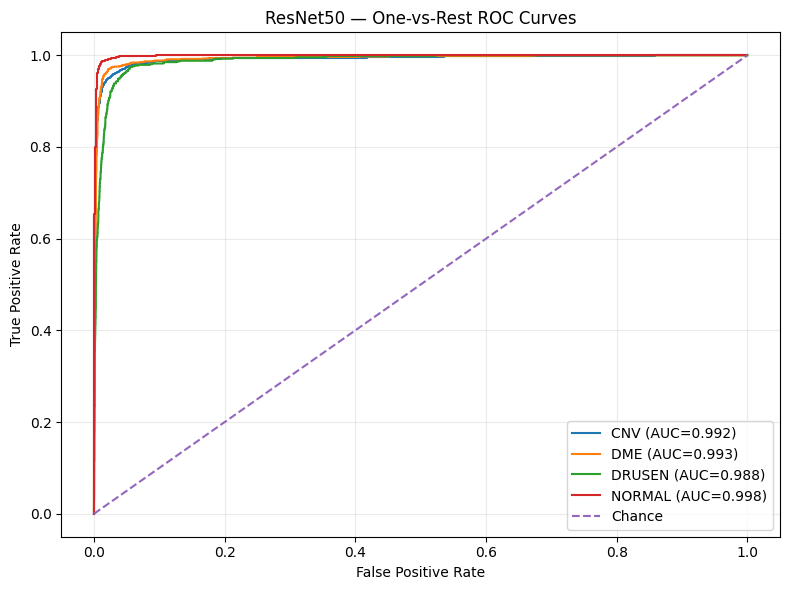

Reading: A curve closer to the upper-left and a larger AUC indicate better class discrimination.


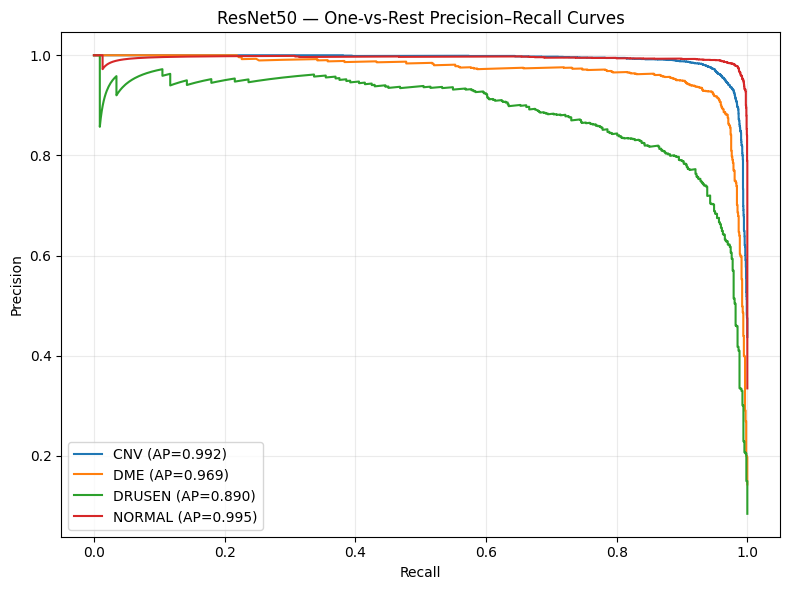

Reading: Higher precision at the same recall is better; AP summarizes each class curve.
Timing note: milliseconds/image includes test data loading, transfer, and model execution.
\n====================================================================== \nTraining: DenseNet121
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 145MB/s] 
/tmp/ipykernel_120/844640498.py:120: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


DenseNet121 | epoch 1/5 | loss=0.2408 | val_macro_F1=0.9384 | minutes=7.4


/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


DenseNet121 | epoch 2/5 | loss=0.1635 | val_macro_F1=0.9442 | minutes=7.3


/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


DenseNet121 | epoch 3/5 | loss=0.1368 | val_macro_F1=0.9345 | minutes=7.3


/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


DenseNet121 | epoch 4/5 | loss=0.1217 | val_macro_F1=0.9495 | minutes=7.4


/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


DenseNet121 | epoch 5/5 | loss=0.1098 | val_macro_F1=0.9438 | minutes=7.4


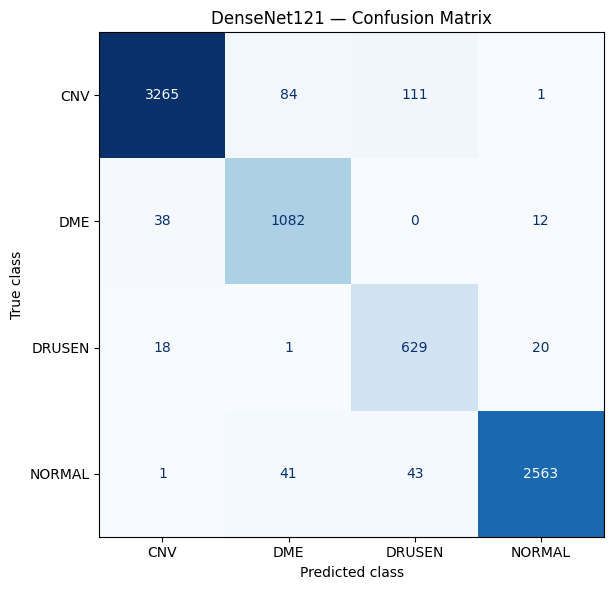

Reading: Diagonal cells are correct predictions; off-diagonal cells show which classes are confused.


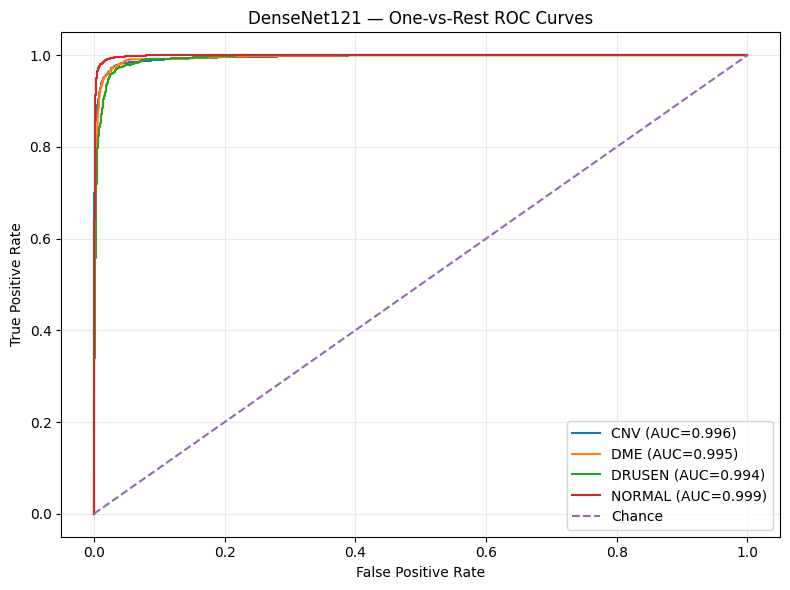

Reading: A curve closer to the upper-left and a larger AUC indicate better class discrimination.


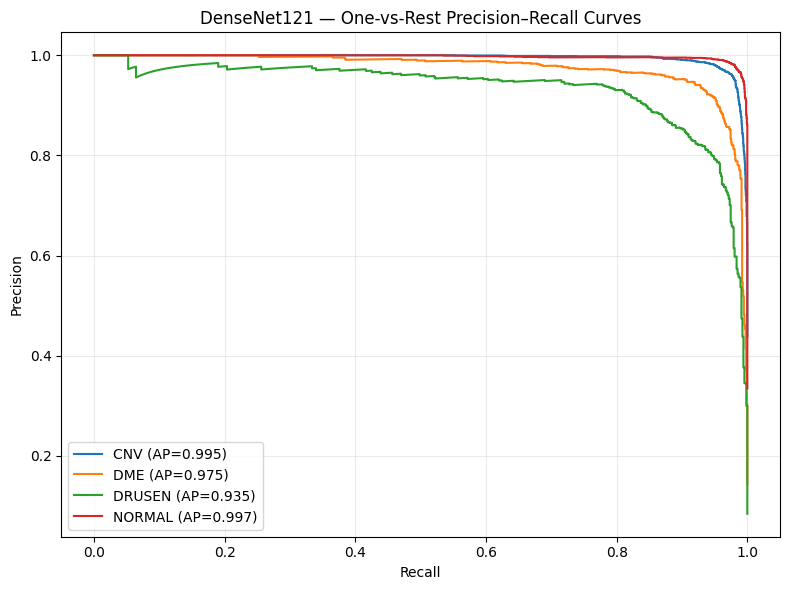

Reading: Higher precision at the same recall is better; AP summarizes each class curve.
Timing note: milliseconds/image includes test data loading, transfer, and model execution.
\n====================================================================== \nTraining: EfficientNet-B0
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 133MB/s] 
/tmp/ipykernel_120/844640498.py:120: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


EfficientNet-B0 | epoch 1/5 | loss=0.2800 | val_macro_F1=0.9195 | minutes=5.4


/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


EfficientNet-B0 | epoch 2/5 | loss=0.1661 | val_macro_F1=0.9320 | minutes=5.0


/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


EfficientNet-B0 | epoch 3/5 | loss=0.1342 | val_macro_F1=0.9374 | minutes=5.0


/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


EfficientNet-B0 | epoch 4/5 | loss=0.1158 | val_macro_F1=0.9346 | minutes=5.0


/tmp/ipykernel_120/844640498.py:134: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


EfficientNet-B0 | epoch 5/5 | loss=0.0985 | val_macro_F1=0.9414 | minutes=5.0


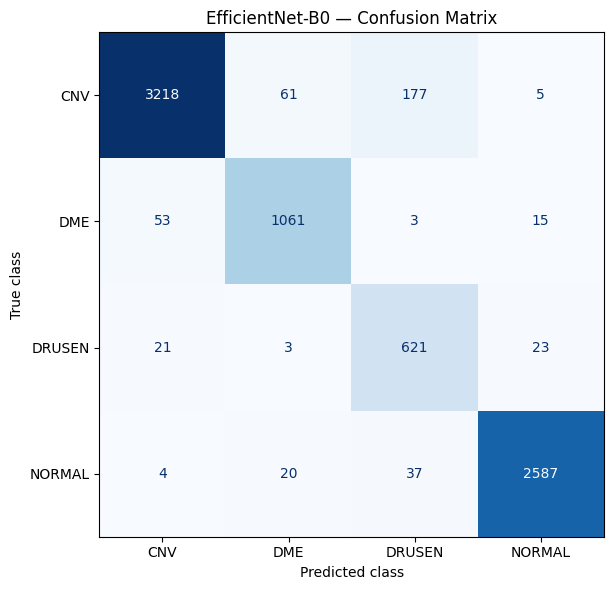

Reading: Diagonal cells are correct predictions; off-diagonal cells show which classes are confused.


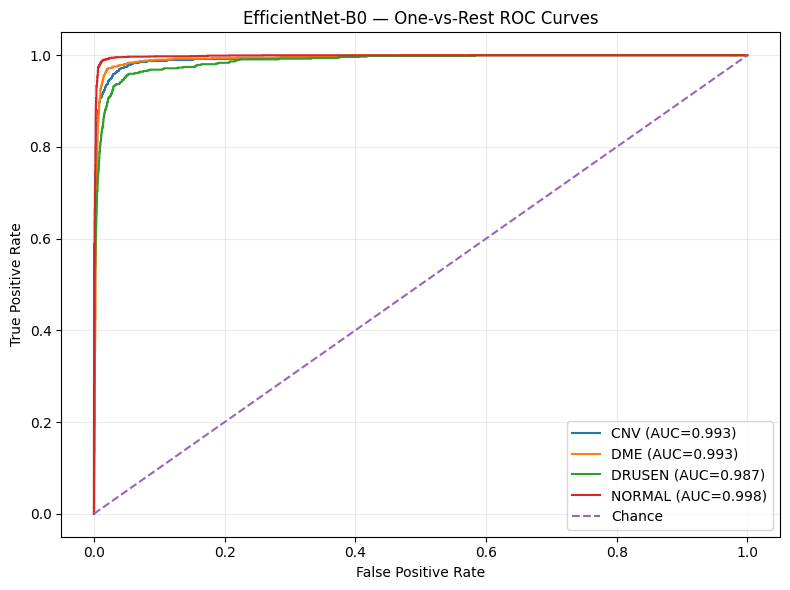

Reading: A curve closer to the upper-left and a larger AUC indicate better class discrimination.


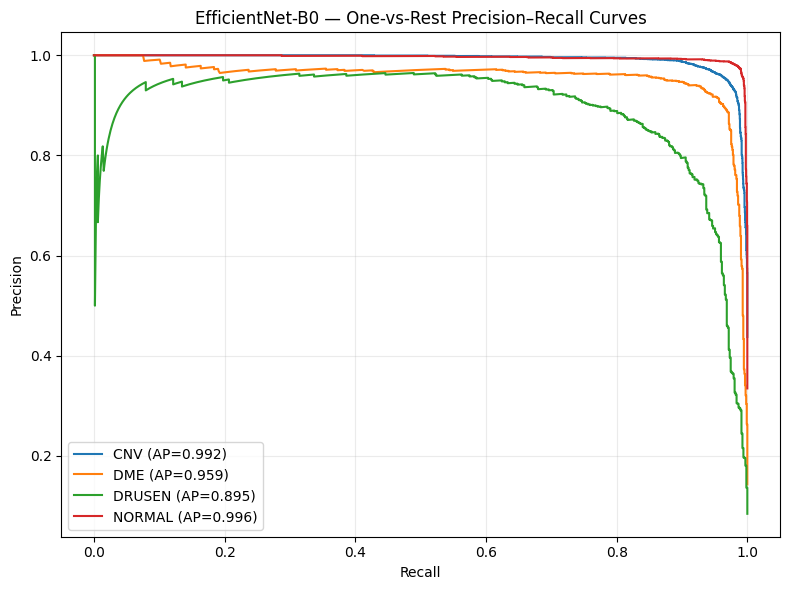

Reading: Higher precision at the same recall is better; AP summarizes each class curve.
Timing note: milliseconds/image includes test data loading, transfer, and model execution.


,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,macro_roc_auc_ovr,weighted_roc_auc_ovr,...,DRUSEN_average_precision,NORMAL_precision,NORMAL_recall,NORMAL_f1,NORMAL_roc_auc,NORMAL_average_precision,training_minutes,total_parameters,trainable_parameters,model_size_mb
0,MobileNetV2,0.955494,0.925765,0.945747,0.935237,0.956932,0.955494,0.955936,0.994807,0.996197,...,0.933747,0.980726,0.979985,0.980355,0.998110,0.994045,24.486952,2228996,2228996,8.739024
2,DenseNet121,0.953218,0.917286,0.952179,0.932993,0.956695,0.953218,0.954145,0.995782,0.996405,...,0.934631,0.987288,0.967900,0.977498,0.998696,0.997161,36.820531,6957956,6957956,27.125753
1,ResNet50,0.946643,0.905506,0.946207,0.923359,0.951567,0.946643,0.947841,0.992955,0.993998,...,0.890069,0.981453,0.979230,0.980340,0.998254,0.994737,26.573275,23516228,23516228,90.012424
3,EfficientNet-B0,0.946643,0.906918,0.943418,0.922355,0.951799,0.946643,0.948065,0.992763,0.994220,...,0.895022,0.983650,0.976964,0.980296,0.998064,0.995754,25.456609,4012672,4012672,15.596257


In [5]:
#Train four CNN baselines
def build_model(name):
    if name == "MobileNetV2":
        weights = models.MobileNet_V2_Weights.DEFAULT if USE_PRETRAINED else None
        model = models.mobilenet_v2(weights=weights)
        model.classifier[1] = nn.Linear(model.last_channel, len(CLASSES))
    elif name == "ResNet50":
        weights = models.ResNet50_Weights.DEFAULT if USE_PRETRAINED else None
        model = models.resnet50(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
    elif name == "DenseNet121":
        weights = models.DenseNet121_Weights.DEFAULT if USE_PRETRAINED else None
        model = models.densenet121(weights=weights)
        model.classifier = nn.Linear(model.classifier.in_features, len(CLASSES))
    elif name == "EfficientNet-B0":
        weights = models.EfficientNet_B0_Weights.DEFAULT if USE_PRETRAINED else None
        model = models.efficientnet_b0(weights=weights)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(CLASSES))
    else:
        raise ValueError(name)
    return model

baseline_results = []
for name in ["MobileNetV2", "ResNet50", "DenseNet121", "EfficientNet-B0"]:
    print("\\n" + "=" * 70, "\\nTraining:", name)
    model = build_model(name)
    total_params, trainable_params = count_parameters(model)
    model, train_seconds, checkpoint = train_model(model, name, BASELINE_EPOCHS)
    result, _ = evaluate_model(model, name)
    result.update({
        "training_minutes": train_seconds / 60,
        "total_parameters": total_params,
        "trainable_parameters": trainable_params,
        "model_size_mb": checkpoint.stat().st_size / (1024 ** 2)
    })
    baseline_results.append(result)
    pd.DataFrame(baseline_results).to_csv(OUTPUT_DIR / "cnn_baseline_results.csv", index=False)
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

baseline_df = pd.DataFrame(baseline_results).sort_values("macro_f1", ascending=False)
display(baseline_df)
baseline_df.to_csv(OUTPUT_DIR / "cnn_baseline_comparison.csv", index=False)

In [6]:
#Results and saved files
display(baseline_df[[
    "model", "accuracy", "macro_precision", "macro_recall", "macro_f1",
    "weighted_precision", "weighted_recall", "weighted_f1",
    "macro_roc_auc_ovr", "weighted_roc_auc_ovr",
    "macro_average_precision_ovr", "weighted_average_precision_ovr",
    "training_minutes", "inference_ms_per_image",
    "total_parameters", "model_size_mb"
]])
print("Saved to:", OUTPUT_DIR)

,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,macro_roc_auc_ovr,weighted_roc_auc_ovr,macro_average_precision_ovr,weighted_average_precision_ovr,training_minutes,inference_ms_per_image,total_parameters,model_size_mb
0,MobileNetV2,0.955494,0.925765,0.945747,0.935237,0.956932,0.955494,0.955936,0.994807,0.996197,0.975943,0.987518,24.486952,3.968315,2228996,8.739024
2,DenseNet121,0.953218,0.917286,0.952179,0.932993,0.956695,0.953218,0.954145,0.995782,0.996405,0.975478,0.987730,36.820531,4.162296,6957956,27.125753
1,ResNet50,0.946643,0.905506,0.946207,0.923359,0.951567,0.946643,0.947841,0.992955,0.993998,0.961465,0.980902,26.573275,4.149732,23516228,90.012424
3,EfficientNet-B0,0.946643,0.906918,0.943418,0.922355,0.951799,0.946643,0.948065,0.992763,0.994220,0.960443,0.980355,25.456609,3.889021,4012672,15.596257


Saved to: /kaggle/working/oct_task2_final


In [7]:

import os
import shutil
from pathlib import Path

SOURCE_DIR = Path("/kaggle/working/oct_task2_final")

ZIP_PATH = Path("/kaggle/working/oct_task2_final.zip")

if not SOURCE_DIR.exists():
    raise FileNotFoundError(f"Folder not found: {SOURCE_DIR}")

shutil.make_archive(
    str(ZIP_PATH.with_suffix("")),
    "zip",
    root_dir=SOURCE_DIR
)

print("ZIP archive created successfully!")
print("Location:", ZIP_PATH)
print("Size: {:.2f} MB".format(ZIP_PATH.stat().st_size / (1024 * 1024)))


ZIP archive created successfully!
Location: /kaggle/working/oct_task2_final.zip
Size: 139.56 MB
